In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
class GeneExpressionsStats:
    def __init__(self, expression_array):
        self.data = expression_array

    def calculate_mean_self(self):
        self.means = np.mean(self.data)
        return self.means

expressions = np.array([1,2,3,4,5])
gene = GeneExpressionsStats(expressions)
print(gene.calculate_mean_self())

3.0


In [3]:
x = torch.tensor([2.0], requires_grad = True)
y = x**2
target = torch.tensor([3])
l = (x-target)**2
print((l.backward()))



None


In [4]:
class LinearNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(input_size,hidden_size))
        self.bias = nn.Parameter(torch.randn(hidden_size))

    def forward(self,x):
        y1 = torch.matmul(x,self.weight) + self.bias
        y = torch.relu(y1)
        return y

input_s = 10
hidden_s1 = 5
hidden_s2 = 3
output_s = 2
z = torch.tensor([1,0,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.1], dtype = torch.float32)



In [5]:
class MasterMultiLayer(nn.Module):
    def __init__(self, input_s, hidden_s1, hidden_s2, output_s):
        super().__init__()
        self.layer1 = LinearNN(input_s,hidden_s1) #Hidden Layer 1
        self.layer2 = LinearNN(hidden_s1,hidden_s2) #Hidden Layer 2
        self.layerout = LinearNN(hidden_s2, output_s)

    def forward(self,x):
        self.layer1calcs = self.layer1(x)
        self.layer2calcs = self.layer2(self.layer1calcs)
        self.layeroutcalcs = self.layerout(self.layer2calcs)
        return self.layeroutcalcs

model = MasterMultiLayer(10,5,3,2)
t = torch.tensor([2,2])
target = t.reshape(2,)

optimizer = torch.optim.SGD(model.parameters(), lr = 0.02)
for efgh in range(100):
    optimizer.zero_grad()
    prediction = model(z)
    loss = ((prediction - target)**2).mean()
    loss.backward()
    optimizer.step()
    print(loss.item())




0.16212661564350128
0.03359087184071541
0.00855027325451374
0.0024666585959494114
0.0008397557539865375
0.0003699356457218528
0.0002171914529753849
0.00015571826952509582
0.00012283296382520348
0.00010054997255792841
8.34016827866435e-05
6.949445378268138e-05
5.79979459871538e-05
4.8430883907712996e-05
4.0449751395499334e-05
3.378843393875286e-05
2.8223572371643968e-05
2.3577058527735062e-05
1.9697075913427398e-05
1.6455900549772196e-05
1.3747429875365924e-05
1.1484867172839586e-05
9.595052688382566e-06
8.017624168132897e-06
6.698144716210663e-06
5.596523806161713e-06
4.675825039157644e-06
3.906800429831492e-06
3.2644770726619754e-06
2.7280073027213803e-06
2.2792032723373268e-06
1.9045203316636616e-06
1.5914258710836293e-06
1.329645328951301e-06
1.1108456874353578e-06
9.281831125917961e-07
7.758198989904486e-07
6.481883474407368e-07
5.419047965915524e-07
4.5281970528776583e-07
3.7833231658623845e-07
3.1619552487427427e-07
2.641118044266477e-07
2.2066106453166867e-07
1.8442534610585426e

In [16]:
Adj = torch.tensor([
    [1., 1., 0., 1.],
    [1., 1., 1., 0.],
    [0., 1., 1., 1.],
    [1., 0., 1., 1.]
], dtype=torch.float32)

H = torch.tensor([
    [1.0, 0.5, 2.0],
    [2.0, 1.0, 0.0],
    [0.5, 2.0, 1.0],
    [1.5, 1.5, 1.5]
], dtype=torch.float32)
class Layer(nn.Module):
    def __init__(self, gene_numbers, out_features):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(gene_numbers,out_features))
        self.bias = nn.Parameter(torch.randn(out_features))

    def forward(self,A,h):
        Degree_matrix = torch.sum(A,dim=1)
        D_inv = torch.pow(Degree_matrix, -0.5)
        D = torch.diag(D_inv)
        self.Normalized_matrix = D@A@D
        self.Learning_matrix = self.Normalized_matrix@h
        y = torch.relu((self.Learning_matrix@self.weights) + self.bias)
        return y

class GNN(nn.Module):
    def __init__(self, gene_numbers, out_features1, out_features2):
        super().__init__()
        self.layer1 = Layer(gene_numbers,out_features1)
        self.layer2 = Layer(out_features1,out_features2)
        self.decoderlayer = Layer(out_features2,gene_numbers)

    def forward(self,A,h):
        self.layer1calcs = self.layer1(A,h)
        self.layer2calcs = self.layer2(A,self.layer1calcs)
        reconstruct = self.decoderlayer(A,self.layer2calcs)
        return self.layer2calcs, reconstruct




0.9081956744194031
0.8861637115478516
0.8652822375297546
0.8448650240898132
0.8248102068901062
0.8053328394889832
0.7865243554115295
0.7683253884315491
0.7506561875343323
0.7335453629493713
0.7170822024345398
0.7012993693351746
0.6861569285392761
0.6716057658195496
0.6576418876647949
0.6442943215370178
0.6315823197364807
0.6194894909858704
0.6079760789871216
0.5970125794410706
0.586592972278595
0.5767152309417725
0.5673596858978271
0.5584880709648132
0.5500629544258118
0.5420622229576111
0.534473717212677
0.5272801518440247
0.5204518437385559
0.5139548182487488
0.5077641606330872
0.5018646717071533
0.49624061584472656
0.49087008833885193
0.48572778701782227
0.480794757604599
0.47606348991394043
0.47152575850486755
0.4671664535999298
0.46297189593315125
0.4589345455169678
0.4550509452819824
0.4513167440891266
0.4477252662181854
0.44426873326301575
0.4409465491771698
0.43775948882102966
0.434704452753067
0.4317775070667267
0.4289771020412445
0.4263033866882324
0.42375648021698
0.42133104

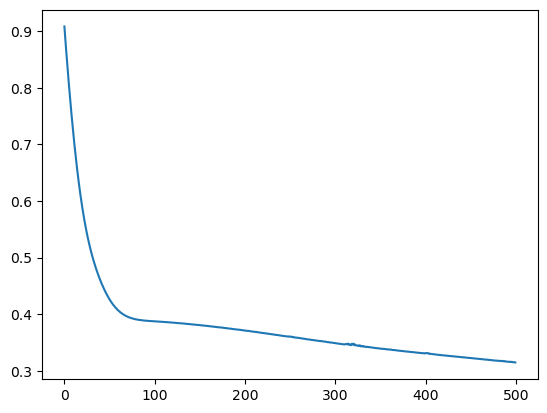

In [31]:
history = []
modelz = GNN(3, 2, 1)
optimizer = torch.optim.Adam(modelz.parameters(), lr=0.01)
criterion = torch.nn.MSELoss()
for epoch in range(500):
    optimizer.zero_grad()
    latent, reconstructed  = modelz(Adj,H)
    loss = criterion(reconstructed, H)
    loss.backward()
    optimizer.step()
    print(loss.item())
    history.append(loss.item())

plt.plot(history)